#About Dataset

The dataset contains images of game duck hunt and different poses of characters in it. Model identifies them

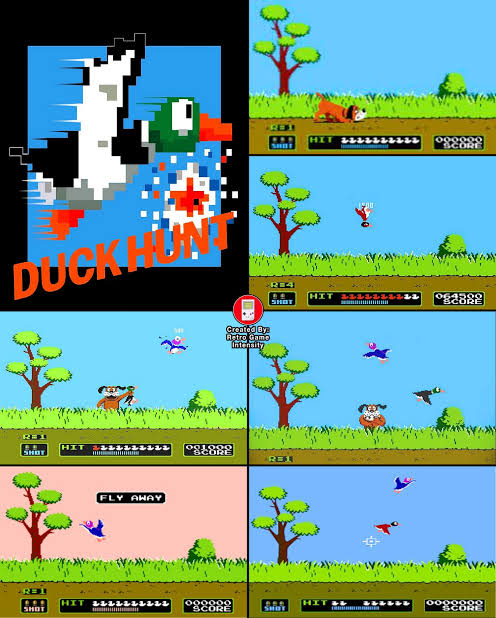

In [1]:
!pip install ultralytics -q

In [2]:
import torch
import ultralytics

print("PyTorch Version:", torch.__version__)
print("Ultralytics Version:", ultralytics.__version__)

if torch.cuda.is_available():
    print("GPU Available:", torch.cuda.get_device_name(0))
else:
    print("GPU Not Available")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch Version: 2.14.1+cu130
Ultralytics Version: 8.4.215
GPU Available: Tesla T4


In [3]:
import os
import yaml
import shutil
import matplotlib.pyplot as plt
import pandas as pd

from google.colab import files
from ultralytics import YOLO

In [4]:
uploaded = files.upload()

Saving Duck_hunt_duo_images.zip to Duck_hunt_duo_images.zip


In [5]:
import zipfile

zip_path = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/')

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [6]:
dataset_path = '/content/yolo_dataset_augmented'

print("Dataset folders:")

for root, dirs, files_list in os.walk(dataset_path):
    level = root.replace(dataset_path, '').count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

print("\nTraining Images:",
      len(os.listdir(dataset_path + '/images/train')))

print("Validation Images:",
      len(os.listdir(dataset_path + '/images/val')))

print("Training Labels:",
      len(os.listdir(dataset_path + '/labels/train')))

print("Validation Labels:",
      len(os.listdir(dataset_path + '/labels/val')))

Dataset folders:
yolo_dataset_augmented/
  images/
    val/
    train/
  labels/
    val/
    train/

Training Images: 711
Validation Images: 260
Training Labels: 711
Validation Labels: 260


#Data Inspection and Visualization

In [7]:
from collections import Counter

classes = ['dog', 'duck_dead', 'duck_shot', 'duck_flying']

label_dir = dataset_path + '/labels/train'

class_counts = Counter()
invalid_labels = []
total_objects = 0

for filename in os.listdir(label_dir):

    if not filename.endswith('.txt'):
        continue

    filepath = os.path.join(label_dir, filename)

    with open(filepath, 'r') as f:
        lines = f.readlines()

    for line_number, line in enumerate(lines, start=1):

        values = line.strip().split()

        if len(values) != 5:
            invalid_labels.append(filename)
            continue

        try:
            class_id = int(values[0])
            bbox = list(map(float, values[1:]))

            if class_id not in range(4):
                invalid_labels.append(filename)
                continue

            if not all(0 <= x <= 1 for x in bbox):
                invalid_labels.append(filename)
                continue

            class_counts[class_id] += 1
            total_objects += 1

        except ValueError:
            invalid_labels.append(filename)

print("Total annotated objects:", total_objects)

print("\nObject distribution:")

for class_id, class_name in enumerate(classes):
    print(f"{class_name}: {class_counts[class_id]}")

print("\nInvalid annotation entries:", len(invalid_labels))

Total annotated objects: 732

Object distribution:
dog: 132
duck_dead: 240
duck_shot: 136
duck_flying: 224

Invalid annotation entries: 0


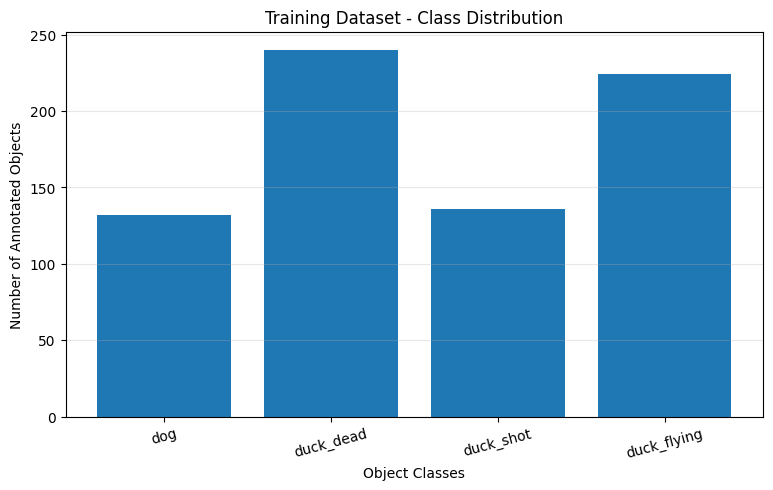

In [8]:
class_names = [classes[i] for i in range(4)]
class_values = [class_counts[i] for i in range(4)]

plt.figure(figsize=(9, 5))

plt.bar(class_names, class_values)

plt.title('Training Dataset - Class Distribution')
plt.xlabel('Object Classes')
plt.ylabel('Number of Annotated Objects')

plt.xticks(rotation=15)
plt.grid(axis='y', alpha=0.3)

plt.show()

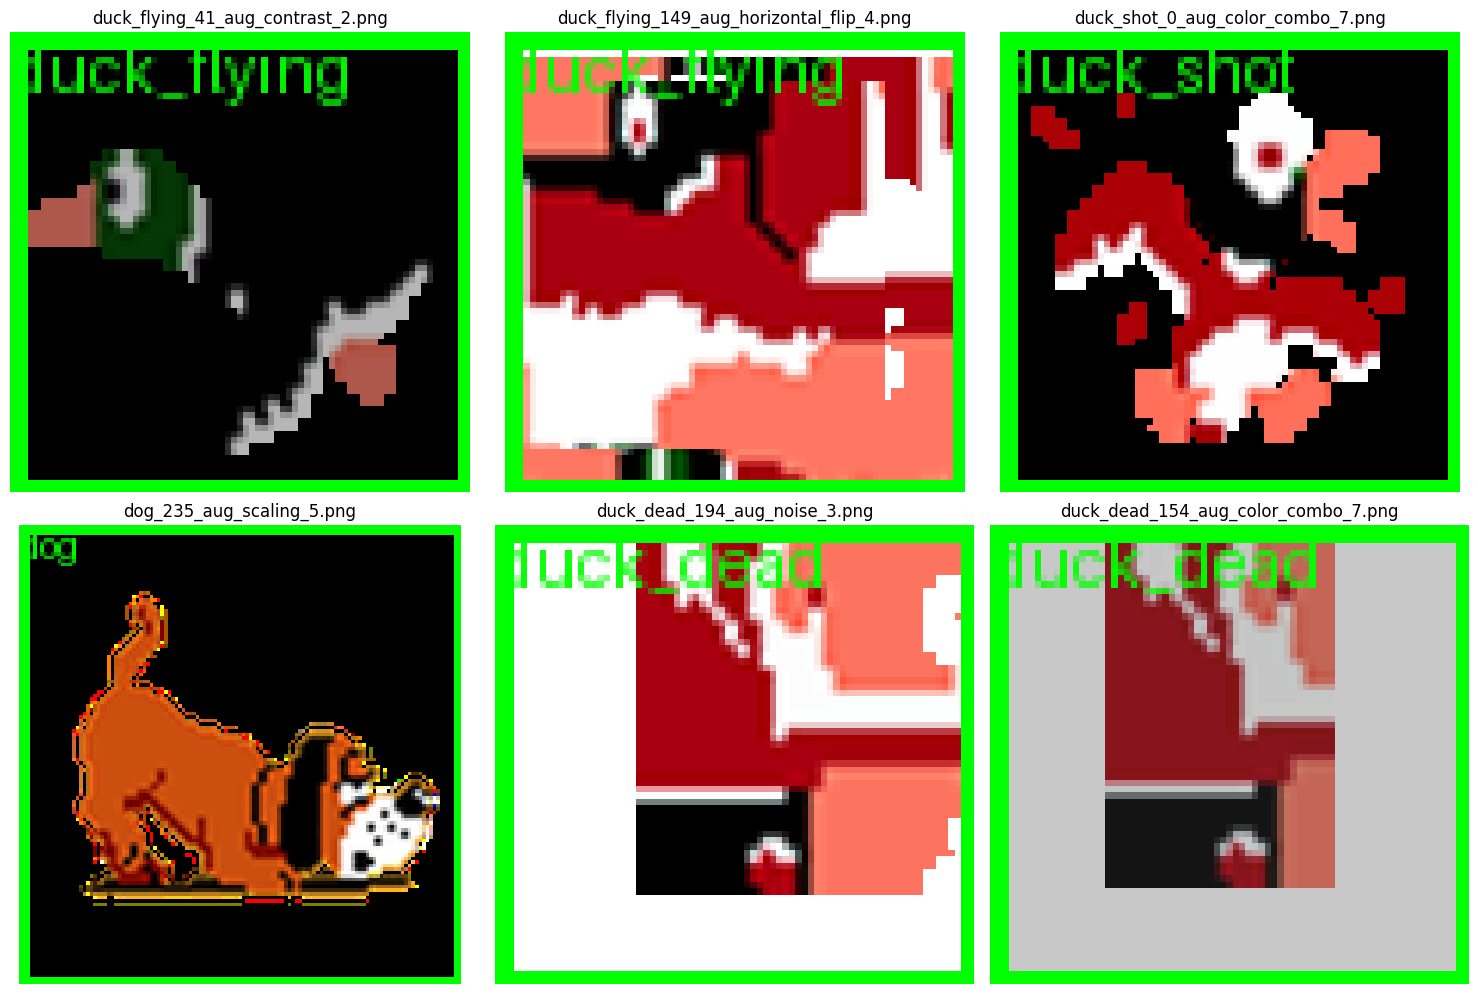

In [9]:
import random
from PIL import Image, ImageDraw

image_dir = dataset_path + '/images/train'
label_dir = dataset_path + '/labels/train'

image_files = [
    f for f in os.listdir(image_dir)
    if f.lower().endswith(('.jpg', '.jpeg', '.png'))
]

sample_images = random.sample(image_files, min(6, len(image_files)))

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for ax, filename in zip(axes, sample_images):

    image_path = os.path.join(image_dir, filename)
    label_path = os.path.join(
        label_dir,
        os.path.splitext(filename)[0] + '.txt'
    )

    image = Image.open(image_path).convert('RGB')

    draw = ImageDraw.Draw(image)

    width, height = image.size

    if os.path.exists(label_path):

        with open(label_path, 'r') as f:
            lines = f.readlines()

        for line in lines:

            values = line.strip().split()

            if len(values) != 5:
                continue

            class_id = int(values[0])
            x_center, y_center, box_width, box_height = map(
                float, values[1:]
            )

            x1 = (x_center - box_width / 2) * width
            y1 = (y_center - box_height / 2) * height
            x2 = (x_center + box_width / 2) * width
            y2 = (y_center + box_height / 2) * height

            draw.rectangle(
                [x1, y1, x2, y2],
                outline='lime',
                width=3
            )

            draw.text(
                (x1, max(0, y1 - 15)),
                classes[class_id],
                fill='lime'
            )

    ax.imshow(image)
    ax.set_title(filename)
    ax.axis('off')

plt.tight_layout()
plt.show()

#Train YOLO

In [10]:
from ultralytics import YOLO

model = YOLO('yolov8n.pt')

print("Pretrained YOLOv8n model loaded successfully!")

Pretrained YOLOv8n model loaded successfully!


In [16]:
results = model.train(
    data="/content/yolo_dataset_augmented/data.yaml",
    epochs=30,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    project='/content/duck_hunt_project',
    name='yolov8n_duck_detection',
    pretrained=True,
    patience=10,
    plots=True,
    save=True,
    verbose=True
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_dataset_augmented/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_duck_detection-2, nbs=64, nms=None, op

In [18]:
import os

print("Searching for YOLO training results...\n")

for root, dirs, files_list in os.walk('/content'):

    if 'results.csv' in files_list:
        print("Results found:", os.path.join(root, 'results.csv'))

    if 'best.pt' in files_list:
        print("Best model found:", os.path.join(root, 'best.pt'))

Searching for YOLO training results...

Results found: /content/duck_hunt_project/yolov8n_duck_detection-2/results.csv
Best model found: /content/duck_hunt_project/yolov8n_duck_detection-2/weights/best.pt


In [19]:
import glob
import pandas as pd
import os

csv_files = glob.glob('/content/**/results.csv', recursive=True)

if csv_files:

    results_csv = csv_files[-1]

    results_dir = os.path.dirname(results_csv)

    print("Training Results Directory:", results_dir)

    df_results = pd.read_csv(results_csv)

    print("\nTotal Completed Epochs:", len(df_results))

    print("\nLast 5 Epochs:")
    display(df_results.tail())

    print("\nBest mAP50:")
    print(df_results['metrics/mAP50(B)'].max())

    print("\nBest mAP50-95:")
    print(df_results['metrics/mAP50-95(B)'].max())

else:
    print("No results.csv file found!")

Training Results Directory: /content/duck_hunt_project/yolov8n_duck_detection-2

Total Completed Epochs: 30

Last 5 Epochs:


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
25,26,277.967,0.12158,0.11432,1.00723,0.99429,0.99417,0.995,0.93709,0.43105,0.36101,1.02242,0.000219,0.000219,0.000219
26,27,287.634,0.11941,0.10917,0.99680,0.98480,0.95661,0.995,0.93596,0.40127,0.37285,0.98675,0.000178,0.000178,0.000178
27,28,297.944,0.11858,0.10462,0.99097,0.98883,0.97695,0.995,0.92312,0.41397,0.37031,1.00883,0.000136,0.000136,0.000136
28,29,307.958,0.11818,0.10045,0.99129,0.98963,0.98846,0.995,0.93442,0.39392,0.34539,0.96959,0.000095,0.000095,0.000095
29,30,316.898,0.10080,0.09323,0.96907,0.98819,0.98098,0.995,0.92990,0.41543,0.36094,1.01946,0.000054,0.000054,0.000054



Best mAP50:
0.995

Best mAP50-95:
0.93709


In [20]:
best_model_files = glob.glob('/content/**/best.pt', recursive=True)

if best_model_files:
    best_model_path = best_model_files[-1]

    print("Best Model Found!")
    print("Model Path:", best_model_path)
    print("File Size:", round(os.path.getsize(best_model_path) / (1024**2), 2), "MB")

else:
    print("best.pt not found!")

Best Model Found!
Model Path: /content/duck_hunt_project/yolov8n_duck_detection-2/weights/best.pt
File Size: 6.2 MB


#Best Model Evaluation

In [22]:
from ultralytics import YOLO

best_model_path = '/content/duck_hunt_project/yolov8n_duck_detection-2/weights/best.pt'

best_model = YOLO(best_model_path)

print("Best YOLOv8n model loaded successfully!")

validation_results = best_model.val(
    data="/content/yolo_dataset_augmented/data.yaml",
    split='val',
    imgsz=640,
    batch=16,
    device=0,
    plots=True
)

print("\nFINAL VALIDATION RESULTS")
print("========================")

print("Precision:", round(validation_results.box.mp, 4))
print("Recall:", round(validation_results.box.mr, 4))
print("mAP50:", round(validation_results.box.map50, 4))
print("mAP50-95:", round(validation_results.box.map, 4))

Best YOLOv8n model loaded successfully!
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 444.9±374.6 MB/s, size: 7.7 KB)
val: Scanning /content/yolo_dataset_augmented/labels/val.cache... 260 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 260/260 83.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 17/17 4.5it/s 3.8s
                   all        260        272      0.994      0.994      0.995      0.937
                   dog        114        120          1          1      0.995      0.919
             duck_dead         16         16      0.992          1      0.995      0.956
             duck_shot        112        112          1      0.977      0.995      0.944
           duck_flying         18         24      0.986          1      0.995      0.9

In [23]:
print("CLASS-WISE PERFORMANCE")
print("=======================")

class_names = validation_results.names
class_ap50 = validation_results.box.ap50

for class_id, ap in enumerate(class_ap50):

    print(
        f"{class_names[class_id]}: "
        f"mAP50 = {ap:.4f} ({ap * 100:.2f}%)"
    )

CLASS-WISE PERFORMANCE
dog: mAP50 = 0.9950 (99.50%)
duck_dead: mAP50 = 0.9950 (99.50%)
duck_shot: mAP50 = 0.9950 (99.50%)
duck_flying: mAP50 = 0.9950 (99.50%)


In [24]:
import os

results_dir = '/content/duck_hunt_project/yolov8n_duck_detection-2'

print("Available training files:\n")

for filename in sorted(os.listdir(results_dir)):
    print(filename)

Available training files:

BoxF1_curve.png
BoxPR_curve.png
BoxP_curve.png
BoxR_curve.png
args.yaml
confusion_matrix.png
confusion_matrix_normalized.png
labels.jpg
results.csv
results.png
train_batch0.jpg
train_batch1.jpg
train_batch2.jpg
train_batch900.jpg
train_batch901.jpg
train_batch902.jpg
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_labels.jpg
val_batch1_pred.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg
weights


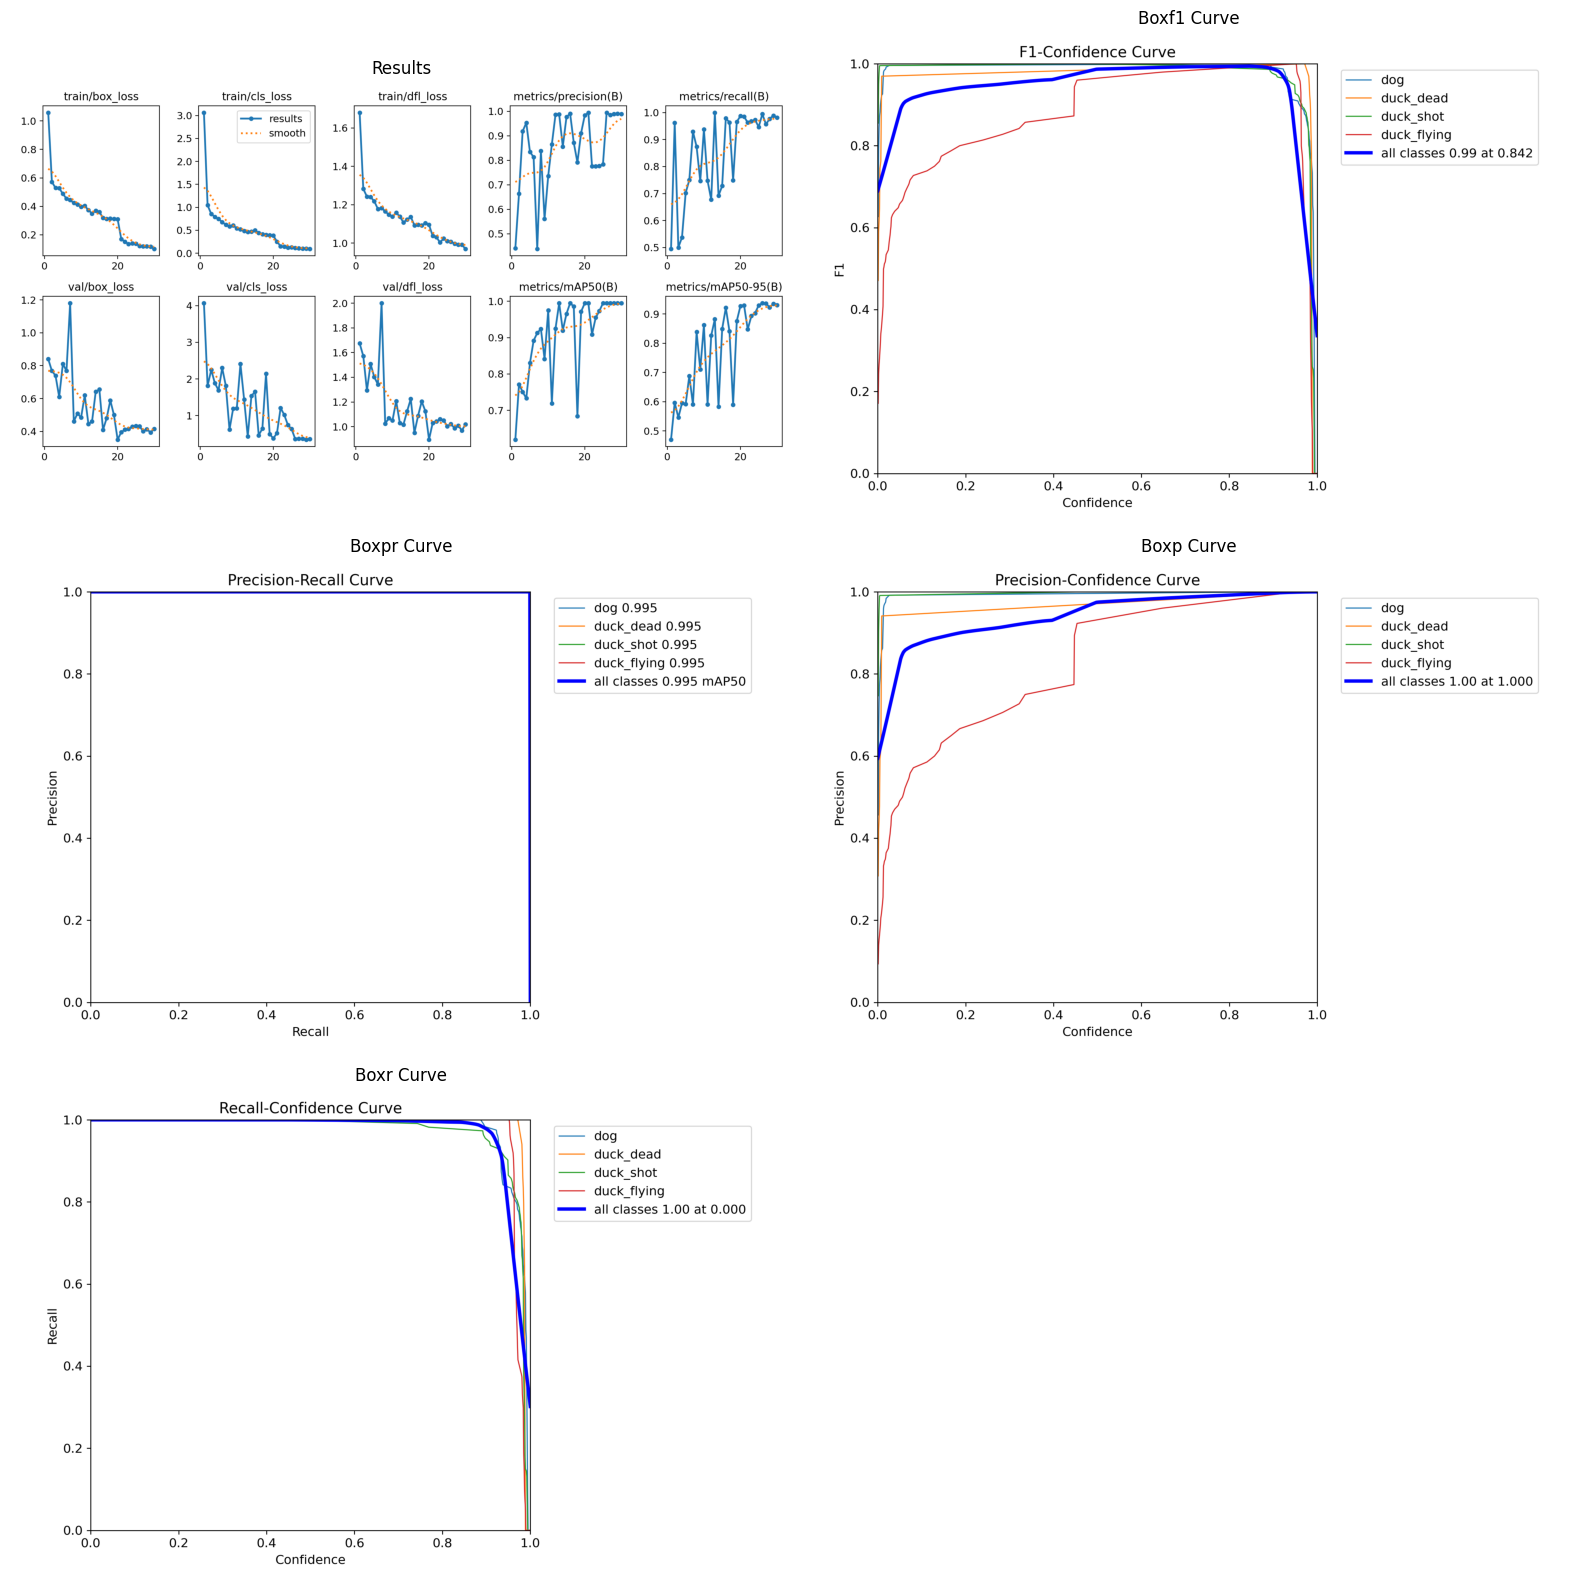

In [25]:
import matplotlib.pyplot as plt
from PIL import Image
import os

graph_files = [
    'results.png',
    'BoxF1_curve.png',
    'BoxPR_curve.png',
    'BoxP_curve.png',
    'BoxR_curve.png'
]

fig, axes = plt.subplots(3, 2, figsize=(16, 16))
axes = axes.flatten()

for i, filename in enumerate(graph_files):

    graph_path = os.path.join(results_dir, filename)

    img = Image.open(graph_path)

    axes[i].imshow(img)
    axes[i].set_title(filename.replace('.png', '').replace('_', ' ').title())
    axes[i].axis('off')

axes[-1].axis('off')

plt.tight_layout()
plt.show()

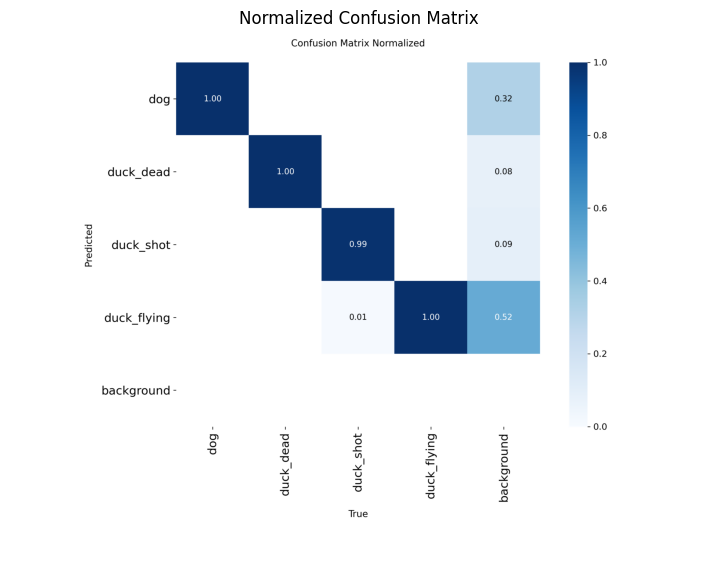

In [26]:
confusion_path = os.path.join(
    results_dir,
    'confusion_matrix_normalized.png'
)

plt.figure(figsize=(9, 7))

plt.imshow(Image.open(confusion_path))
plt.title('Normalized Confusion Matrix')
plt.axis('off')

plt.show()

#Object Detection on Images

In [27]:
import random
import os

val_image_dir = dataset_path + '/images/val'

image_files = [
    f for f in os.listdir(val_image_dir)
    if f.lower().endswith(('.jpg', '.jpeg', '.png'))
]

test_image = os.path.join(
    val_image_dir,
    random.choice(image_files)
)

print("Selected Test Image:", os.path.basename(test_image))

Selected Test Image: duck_shot_224_aug_color_combo_7.png


In [28]:
prediction_results = best_model.predict(
    source=test_image,
    conf=0.25,
    imgsz=640,
    save=True,
    verbose=False
)

print("Prediction completed successfully!")

Results saved to /content/runs/detect/predict
Prediction completed successfully!


In [29]:
result = prediction_results[0]

detected_objects = []

for box in result.boxes:

    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    detected_objects.append({
        'Object': result.names[class_id],
        'Confidence': round(confidence, 4)
    })

print("DETECTED OBJECTS")
print("================")

if detected_objects:
    for obj in detected_objects:
        print(
            f"{obj['Object']} - "
            f"Confidence: {obj['Confidence'] * 100:.2f}%"
        )
else:
    print("No objects detected.")

print("\nTotal Objects Detected:", len(detected_objects))

DETECTED OBJECTS
duck_shot - Confidence: 98.66%

Total Objects Detected: 1


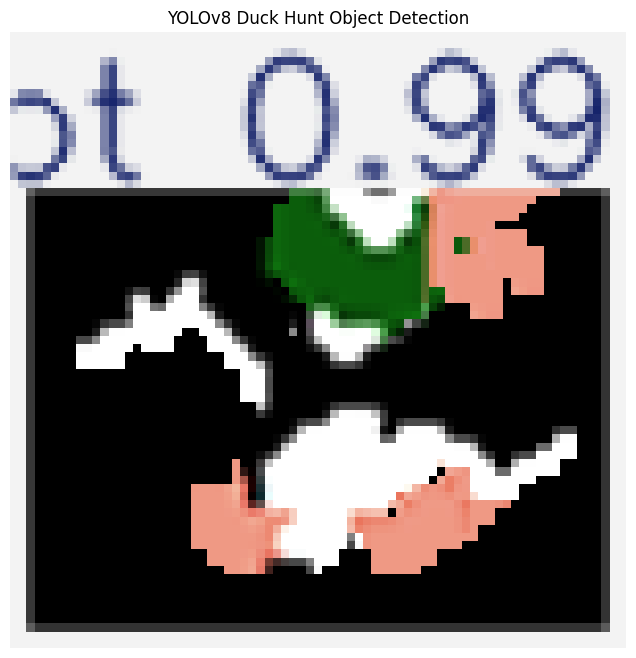

In [30]:
annotated_image = result.plot()

plt.figure(figsize=(12, 8))
plt.imshow(
    __import__('cv2').cvtColor(
        annotated_image,
        __import__('cv2').COLOR_BGR2RGB
    )
)

plt.title('YOLOv8 Duck Hunt Object Detection')
plt.axis('off')
plt.show()

#Deploying on Streamlit

In [31]:
import os
import shutil

app_dir = '/content/duck_hunt_streamlit'

os.makedirs(app_dir, exist_ok=True)

best_model_path = '/content/duck_hunt_project/yolov8n_duck_detection-2/weights/best.pt'

shutil.copy(
    best_model_path,
    os.path.join(app_dir, 'best.pt')
)

print("Model copied successfully!")
print("Model size:",
      round(os.path.getsize(app_dir + '/best.pt') / (1024 * 1024), 2),
      "MB")

Model copied successfully!
Model size: 6.2 MB


In [32]:
%%writefile /content/duck_hunt_streamlit/app.py

import streamlit as st
import pandas as pd
from ultralytics import YOLO
from PIL import Image
import os

st.set_page_config(
    page_title="Duck Hunt Object Detector",
    page_icon="🦆",
    layout="wide"
)

st.title("🦆 Duck Hunt Object Detector")

st.write(
    "Upload an image to detect dogs and different duck categories "
    "using our trained YOLOv8 model."
)

@st.cache_resource
def load_model():
    model_path = os.path.join(
        os.path.dirname(__file__),
        "best.pt"
    )
    return YOLO(model_path)

model = load_model()

st.subheader("Upload Image")

uploaded_file = st.file_uploader(
    "Choose an image",
    type=["jpg", "jpeg", "png"]
)

confidence = st.slider(
    "Confidence Threshold",
    min_value=0.05,
    max_value=0.95,
    value=0.25,
    step=0.05
)

if uploaded_file is not None:

    image = Image.open(uploaded_file).convert("RGB")

    st.subheader("Original Image")
    st.image(image, use_container_width=True)

    if st.button("Detect Objects", type="primary"):

        with st.spinner("Detecting objects..."):

            results = model.predict(
                source=image,
                conf=confidence,
                imgsz=640,
                verbose=False
            )

            result = results[0]

        st.subheader("Detection Results")

        annotated_image = result.plot()

        annotated_image = Image.fromarray(
            annotated_image[:, :, ::-1]
        )

        col1, col2 = st.columns(2)

        with col1:
            st.image(
                annotated_image,
                caption="Detected Objects",
                use_container_width=True
            )

        detections = []

        for box in result.boxes:

            class_id = int(box.cls[0])
            score = float(box.conf[0])

            detections.append({
                "Object": result.names[class_id],
                "Confidence": f"{score * 100:.2f}%"
            })

        with col2:

            st.metric(
                "Total Objects Detected",
                len(detections)
            )

            if detections:

                st.success("Objects detected successfully!")

                st.dataframe(
                    pd.DataFrame(detections),
                    use_container_width=True,
                    hide_index=True
                )

            else:
                st.warning("No objects detected. Try lowering the confidence threshold.")

st.divider()

st.subheader("Supported Classes")

st.write(
    "🐕 Dog | 🦆 Dead Duck | 🦆 Shot Duck | 🦆 Flying Duck"
)

st.caption("Powered by YOLOv8n and Ultralytics.")

Writing /content/duck_hunt_streamlit/app.py


In [37]:
%%writefile /content/duck_hunt_streamlit/requirements.txt

ultralytics==8.4.215
streamlit
pandas
pillow

Overwriting /content/duck_hunt_streamlit/requirements.txt
